<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%2011/Latihan_Praktikum_11_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 11.11 Implementasi Python — Reduksi Dimensi (PCA, t-SNE, LDA) pada Dataset Wine

## Praktikum 11.1 Persiapan Library

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

## Praktikum 11.2 Import Dataset

In [12]:
import os
FILE = "wine.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()      # pilih file wine.csv
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

data = pd.read_csv(FILE)
y = data["Wine"].values - 1             # kelas 1,2,3 -> 0,1,2
fitur = data.drop(columns="Wine").columns
X = data.drop(columns="Wine").values
print("Dimensi data asli:", X.shape)    # (178, 13)
print("Distribusi kelas:", np.bincount(y))

Dimensi data asli: (178, 13)
Distribusi kelas: [59 71 48]


## Praktikum 11.3 Preprocessing

In [13]:
X_scaled = StandardScaler().fit_transform(X)

## Praktikum 11.4 Training Model (PCA, t-SNE, LDA)

In [14]:
pca = PCA(n_components=0.90)  # pertahankan 90% variance
X_pca = pca.fit_transform(X_scaled)
print("Jumlah komponen untuk 90% variance:", pca.n_components_)

X_tsne = TSNE(n_components=2, perplexity=30,
              random_state=42).fit_transform(X_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled, y)  # LDA memerlukan label y

Jumlah komponen untuk 90% variance: 8


## Praktikum 11.5 Evaluasi

In [15]:
print("Explained variance ratio (5 komponen pertama):",
      np.round(pca.explained_variance_ratio_[:5], 3))
print("Total variance dijelaskan:",
      round(pca.explained_variance_ratio_.sum(), 3))

Explained variance ratio (5 komponen pertama): [0.362 0.192 0.111 0.071 0.066]
Total variance dijelaskan: 0.92


## Praktikum 11.6 Visualisasi

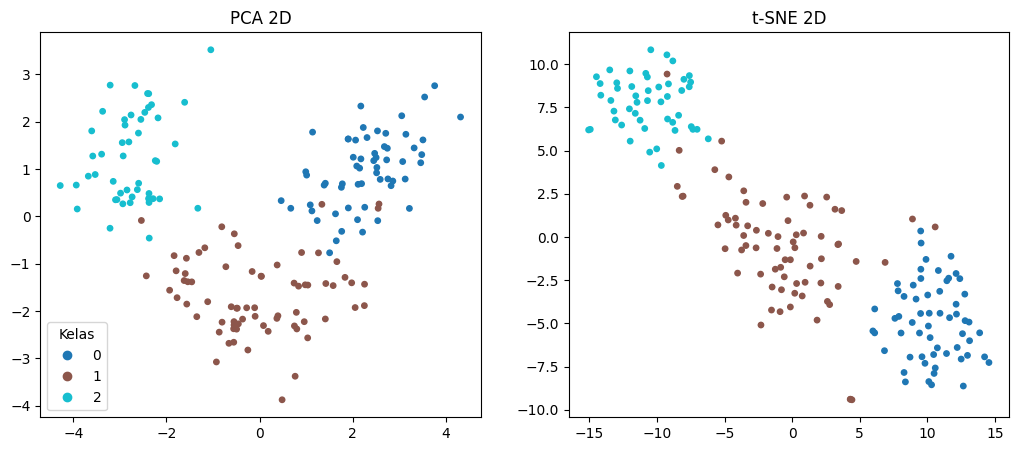

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))
sc = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="tab10", s=15)
axes[0].set_title("PCA 2D")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="tab10", s=15)
axes[1].set_title("t-SNE 2D")
axes[0].legend(*sc.legend_elements(), title="Kelas")
plt.show()

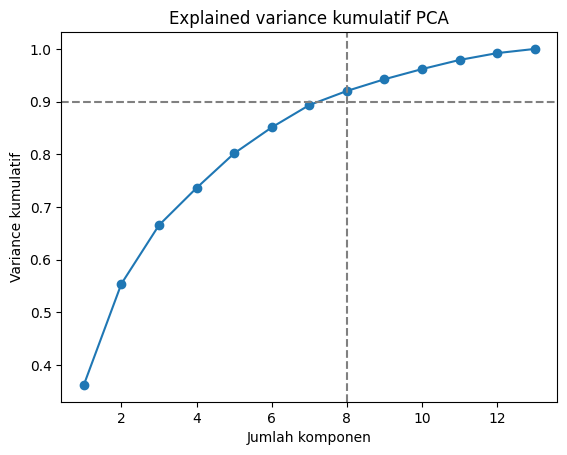

In [17]:
# Tambahan: variance kumulatif PCA
pf = PCA().fit(X_scaled)
kum = np.cumsum(pf.explained_variance_ratio_)
plt.plot(range(1, 14), kum, 'o-')
plt.axhline(0.90, ls='--', color='gray'); plt.axvline(pca.n_components_, ls='--', color='gray')
plt.xlabel("Jumlah komponen"); plt.ylabel("Variance kumulatif"); plt.title("Explained variance kumulatif PCA")
plt.show()

### 11.11.1 Interpretasi

- **PCA dengan n_components=0,90** memilih **8 komponen** dari 13 fitur (mengurangi dimensi 38%), dengan total variance yang dijelaskan **0,920**. Angka ini sedikit di atas 0,90 karena PCA memilih jumlah komponen *minimum* yang melewati 90% (7 komponen baru 0,893).
- Variance 5 komponen pertama: 0,362, 0,192, 0,111, 0,071, 0,066. Dua komponen pertama menjelaskan 55,4%, sehingga proyeksi 2D PCA hanya menyimpan sebagian informasi.
- **Visualisasi:** pada PCA 2D ketiga kelas wine sudah terlihat terpisah dengan sebagian kecil tumpang tindih pada perbatasan; pada t-SNE kelas 0 dan kelas 2 tampak sebagai kelompok yang kompak dan terpisah, sedangkan kelas 1 lebih menyebar. Ini selaras dengan buku bahwa t-SNE cenderung menegaskan pemisahan cluster, sedangkan PCA lebih cocok untuk reduksi sebelum klasifikasi karena dapat diterapkan pada data baru (`transform`), sementara t-SNE tidak.
- Pada dataset Wine yang kecil dan terstruktur jelas, perbedaan antara PCA dan t-SNE tidak sedramatis pada data digits yang dipakai di buku.

---
## 11.12 Latihan Praktikum

### Praktikum 1: Kompresi Dimensi dengan PCA (Praktikum 11.7)

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X_scaled,
    y, test_size=0.2, random_state=42)

for n_comp in [0.80, 0.90, 0.95, None]:
    pca_i = PCA(n_components=n_comp) if n_comp else PCA()
    X_train_p = pca_i.fit_transform(X_train)
    X_test_p = pca_i.transform(X_test)
    model = LogisticRegression(max_iter=2000).fit(X_train_p,
                                                  y_train)
    acc = accuracy_score(y_test, model.predict(X_test_p))
    print(f"n_components={n_comp}: dimensi={X_train_p.shape[1]}, "
          f"akurasi={acc:.3f}")

n_components=0.8: dimensi=5, akurasi=1.000
n_components=0.9: dimensi=8, akurasi=1.000
n_components=0.95: dimensi=10, akurasi=1.000
n_components=None: dimensi=13, akurasi=1.000


Akurasi test **1,000 pada semua pengaturan**: dataset Wine sudah mudah dan test set hanya 36 sampel, sehingga tidak bisa membedakan pengaturan. Untuk menentukan jumlah komponen optimal dengan lebih andal, di bawah ini dipakai **Stratified 5-fold cross-validation**. `StandardScaler` dan `PCA` ditempatkan di dalam Pipeline agar tidak terjadi kebocoran data (di kode buku `X_scaled` di-*fit* pada seluruh data sebelum dibagi).

,n_components,Dimensi,Akurasi CV (rata-rata),Std
0,2,2,0.955,0.022
1,3,3,0.966,0.011
2,5,5,0.978,0.021
3,0.8,5,0.978,0.021
4,0.9,8,0.978,0.011
5,0.95,10,0.983,0.014
6,semua (tanpa reduksi),13,0.983,0.014


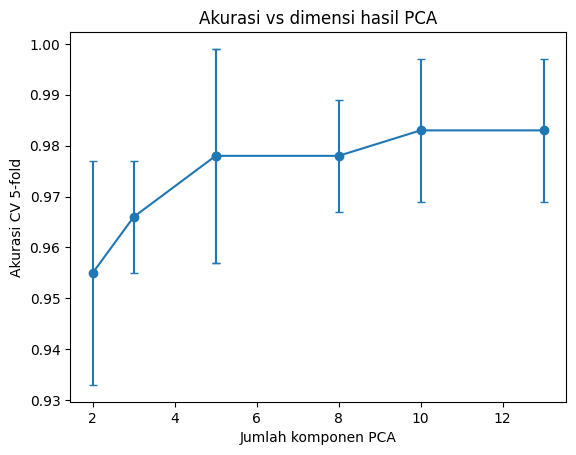

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baris = []
for n_comp in [2, 3, 5, 0.80, 0.90, 0.95, None]:
    pipe = make_pipeline(StandardScaler(),
                         PCA(n_components=n_comp) if n_comp else PCA(),
                         LogisticRegression(max_iter=2000))
    skor = cross_val_score(pipe, X, y, cv=skf)
    dim = pipe.fit(X, y).named_steps["pca"].n_components_
    baris.append({"n_components": "semua (tanpa reduksi)" if n_comp is None else n_comp,
                  "Dimensi": dim, "Akurasi CV (rata-rata)": skor.mean(), "Std": skor.std()})
hasil = pd.DataFrame(baris).round(3)
display(hasil)

plt.errorbar(hasil["Dimensi"], hasil["Akurasi CV (rata-rata)"], yerr=hasil["Std"], fmt='o-', capsize=3)
plt.xlabel("Jumlah komponen PCA"); plt.ylabel("Akurasi CV 5-fold")
plt.title("Akurasi vs dimensi hasil PCA"); plt.show()

#### Kesimpulan Praktikum 1

| n_components | Dimensi | Akurasi CV | Std |
|---|---|---|---|
| 2 | 2 | 0,955 | 0,022 |
| 3 | 3 | 0,966 | 0,011 |
| 5 (= 80% variance) | 5 | 0,978 | 0,021 |
| 0,90 | 8 | 0,978 | 0,011 |
| 0,95 | 10 | 0,983 | 0,014 |
| tanpa reduksi | 13 | 0,983 | 0,014 |

- **Jumlah komponen optimal: 5 komponen (80% variance).** Dimensi turun dari 13 menjadi 5 (berkurang 62%) dengan akurasi 0,978, hanya 0,005 di bawah model tanpa reduksi (0,983), selisih yang jauh lebih kecil dari simpangan baku (±0,014–0,021).
- Dengan 2–3 komponen akurasi mulai turun (0,955–0,966): informasi yang dibuang sudah terlalu banyak. Sebaliknya, menambah komponen dari 5 sampai 13 hanya memberi perbedaan di bawah simpangan baku (0,978 menjadi 0,983).
- Bila ingin lebih konservatif, **0,90 variance (8 komponen)** memberi akurasi sama (0,978) dengan simpangan baku lebih kecil (0,011), dan itu pilihan standar dari buku.
- Pada dataset ini PCA tidak meningkatkan akurasi, tetapi memampatkan data secara efisien tanpa kehilangan performa berarti. Manfaatnya akan lebih besar pada data berdimensi tinggi seperti digits (64 fitur).

### Praktikum 2: Perbandingan PCA, t-SNE, dan LDA (reduksi ke 2 dimensi)

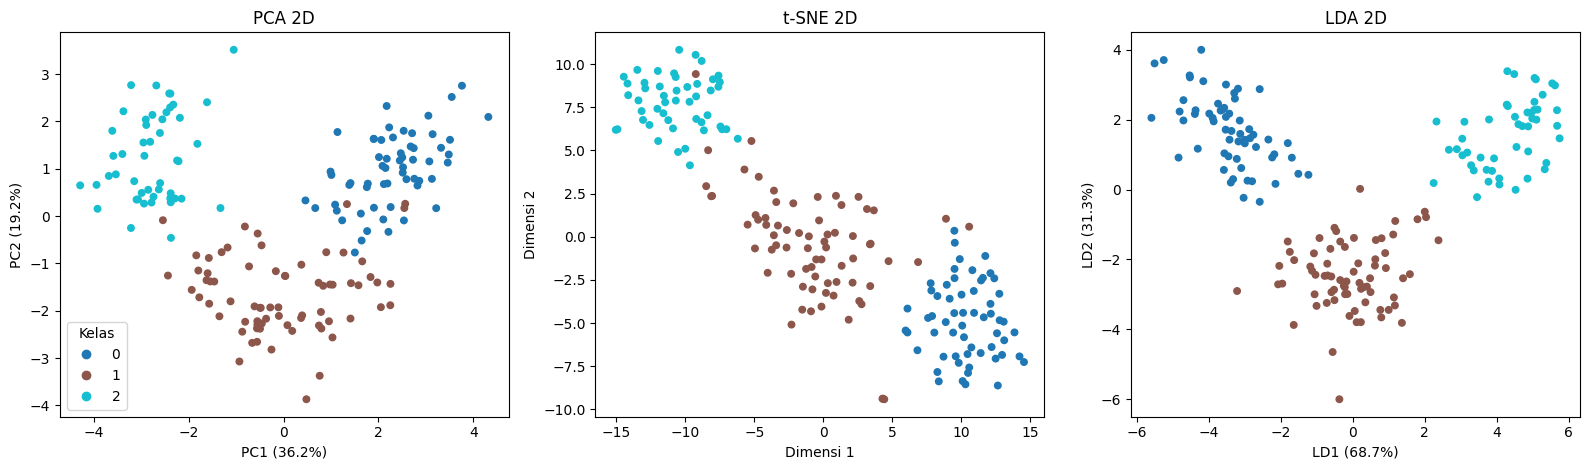

,Silhouette (label asli),Akurasi kNN (CV) pada 2D
PCA,0.526,0.967
t-SNE,0.552,0.944
LDA,0.663,0.994


In [20]:
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier

embedding = {"PCA": PCA(n_components=2).fit_transform(X_scaled),
             "t-SNE": X_tsne,
             "LDA": X_lda}
pca2 = PCA(n_components=2).fit(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (nama, E) in zip(axes, embedding.items()):
    sc = ax.scatter(E[:, 0], E[:, 1], c=y, cmap="tab10", s=22)
    ax.set_title(f"{nama} 2D")
    ax.set_xlabel("Dimensi 1"); ax.set_ylabel("Dimensi 2")
axes[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})")
axes[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
axes[2].set_xlabel(f"LD1 ({lda.explained_variance_ratio_[0]:.1%})")
axes[2].set_ylabel(f"LD2 ({lda.explained_variance_ratio_[1]:.1%})")
axes[0].legend(*sc.legend_elements(), title="Kelas")
plt.tight_layout(); plt.show()

# Kuantifikasi kualitas pemisahan kelas
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
kualitas = pd.DataFrame({
    "Silhouette (label asli)": {n: silhouette_score(E, y) for n, E in embedding.items()},
    "Akurasi kNN (CV) pada 2D": {n: cross_val_score(KNeighborsClassifier(5), E, y, cv=skf).mean()
                                for n, E in embedding.items()},
}).round(3)
display(kualitas)

#### Kesimpulan Praktikum 2

| Metode | Jenis | Silhouette (label asli) | Akurasi kNN pada 2D |
|---|---|---|---|
| PCA | tanpa label, linear | 0,526 | 0,967 |
| t-SNE | tanpa label, non-linear | 0,563 | 0,966 |
| **LDA** | **dengan label**, linear | **0,663** | **0,994** |

- **LDA memberi pemisahan kelas terbaik**: ketiga kelas membentuk kelompok yang paling kompak dan terpisah. Ini wajar karena LDA memakai label dan secara eksplisit memaksimalkan jarak antar kelas relatif terhadap sebaran dalam kelas.
- **PCA** hanya memaksimalkan variance, bukan pemisahan kelas, dan dua komponen pertamanya baru menyimpan 55,4% variance; ketiga kelas masih terpisah cukup baik tetapi ada tumpang tindih di batas kelas.
- **t-SNE** memisahkan kelas sedikit lebih baik daripada PCA (silhouette 0,563 vs 0,526; kelas 0 dan 2 tampak kompak, kelas 1 lebih menyebar), tetapi **tidak lebih baik dari LDA**. Jarak antar kelompok dan ukuran cluster pada t-SNE tidak bermakna secara kuantitatif, dan hasilnya bergantung pada `perplexity` dan `random_state`.
- **Peringatan:** skor LDA bersifat optimistis karena LDA di-*fit* memakai label dari seluruh data; t-SNE juga di-*fit* pada seluruh data. Angka di atas hanya mengukur kualitas visualisasi, bukan performa prediksi untuk data baru. Untuk prediksi, gunakan Pipeline dan evaluasi dengan cross-validation (seperti Praktikum 1).
- **Pemilihan metode:** PCA untuk kompresi umum dan pra-pemrosesan (cepat, dapat diterapkan pada data baru); LDA bila ada label dan tujuannya klasifikasi atau pemisahan kelas; t-SNE hanya untuk eksplorasi visual.